In [1]:
import ROOT, glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os, sys

def browse_files(filenames):
    """
    Browse through the list of filenames and return a sorted list of files.
    """
    if isinstance(filenames, str):
        files = sorted(glob.glob(filenames))
    elif isinstance(filenames, list):
        files = []
        for filename in filenames:
            files += sorted(glob.glob(filename))
    else:
        raise ValueError("Input should be a string or a list of strings.")
    
    return files

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

In [2]:
exponent = 0
dirDir= "/home/users/l/lebrun/"
dataDir = dirDir + "data/"
typeBins = "scaled"
figPath = dirDir + "figures/scaling/" + typeBins + "/" + f"exp{exponent:.1f}/" + typeBins + '_'
dataPath = dirDir + "data/" + typeBins + "_cos_theta_bins/"
dataPath += f"exp{exponent:.1f}/"

files = browse_files(dataPath + "*.root")
rdf = ROOT.RDataFrame("MC", files)

if typeBins == "filtered":
    rdf = rdf.Filter("tt_isHET ==1")

# print columns names
# print("Columns in the RDataFrame:")
# for column in rdf.GetColumnNames():
#     print(column)

In [3]:
# Plot Energy histogram of df which belong to neither HET nor HET
def create_log_bins(min_val, max_val, n_bins):
    """Create logarithmically spaced bin edges"""
    return np.logspace(np.log10(min_val), np.log10(max_val), n_bins + 1)



In [4]:
n_bins = 50
min_val = 1
max_val = 1e4

log_bins = create_log_bins(min_val, max_val, n_bins)
log_bins_root = ROOT.std.vector('double')(log_bins)

# Plot energy histogram
hist = rdf.Histo1D(("E_true", f"Energy Distribution ({typeBins})", n_bins, log_bins_root.data()), "E_true", "weight")
c = ROOT.TCanvas("c", "Energy Distribution", 800, 600)
hist.SetLineColor(ROOT.kBlue)
hist.SetTitle(f"Energy Distribution ({typeBins}); Energy (GeV); Counts")
hist.Draw("HIST")
c.SetLogy()
c.SetLogx()
# Save histogram
if not os.path.exists(figPath):
    os.makedirs(figPath)
c.SaveAs(figPath + "energy_distribution.pdf")
# Draw the histogram
c.Draw()

Info in <TCanvas::Print>: pdf file /home/users/l/lebrun/figures/scaling/scaled/exp0.0/scaled_energy_distribution.pdf has been created


# Study bin by bin

In [5]:
# Create a histogram of the 'cos_theta' column
cos_theta_hist = rdf.Histo1D(("cos_theta", f"Cosine of Theta Distribution ({typeBins})", 40, 0, 1), "cosTheta", "weight")
c_cos_theta = ROOT.TCanvas("c_cos_theta", "Cosine of Theta Distribution", 800, 600)
cos_theta_hist.SetLineColor(ROOT.kRed)
cos_theta_hist.SetTitle(f"Cosine of Theta Distribution ({typeBins}); cos(theta); Counts")
cos_theta_hist.Draw("HIST")
c_cos_theta.SetLogy()
# Save cosine theta histogram
if not os.path.exists(figPath):
    os.makedirs(figPath)
c_cos_theta.SaveAs(figPath + "cos_theta_distribution.pdf")
c_cos_theta.Draw()

Info in <TCanvas::Print>: pdf file /home/users/l/lebrun/figures/scaling/scaled/exp0.0/scaled_cos_theta_distribution.pdf has been created


In [6]:
rdfs = [
    rdf.Filter(f"cosTheta >= {i * 0.05} && cosTheta < {(i + 1) * 0.05}")
    for i in range(20)
]
# Create histograms for each filter
hists = [rdfs[i].Histo1D(ROOT.RDF.TH1DModel(f"h_cosTheta_{i+1}", f"Energy Spectra per cosTheta Bin ({typeBins});Energy [GeV];Counts", n_bins, log_bins_root.data()), "E_true", "weight") for i in range(20)]
# Compute the maximum y value among all histograms
max_y = max(hist.GetMaximum() for hist in hists)
min_y = min(hist.GetMinimum(1) for hist in hists)  # avoid log(0)

# Optionally pad the y-range a bit (for log scale)
max_y *= 1.2
min_y = min_y if min_y > 0 else 1e-3  # ROOT log axis needs > 0

# Set axis range on the first histogram before drawing
hists[0].SetMaximum(max_y)
hists[0].SetMinimum(min_y)
# for i, r in enumerate(rdfs):
#     print(f"Bin {i}: {r.Count().GetValue()} entries")
# print(log_bins_root)
# print(rdf.Max("E_true").GetValue(), rdf.Min("E_true").GetValue())

In [7]:
# Draw histograms on same canvas for comparison
ROOT.gStyle.SetOptStat(0)
c3 = ROOT.TCanvas("c3", "Energy Spectra per cosTheta Bin", 800, 600)
c3.SetLogy()
c3.SetLogx()
colors = [ROOT.kRed, ROOT.kBlue, ROOT.kGreen+2, ROOT.kOrange, ROOT.kViolet, ROOT.kCyan+1,
          ROOT.kMagenta+2, ROOT.kGray+2, ROOT.kPink-3, ROOT.kTeal+3] * 2  # Repeat for 20
for i, hist in enumerate(hists):
    hist.SetLineColor(colors[i])
    hist.SetLineWidth(2)
    if i == 0:
        hist.Draw()  # Draw the first histogram
    else:
        hist.Draw("hist same")  # Draw subsequent histograms on the same canvas
# Add legend
leg2 = ROOT.TLegend(0.75, 0.65, 0.88, 0.88)
for i in range(20):
    leg2.AddEntry(hists[i].GetValue(), f"Bin {i}", "l")
leg2.SetTextSize(0.03)
leg2.Draw("same")
  
# Update canvas
c3.Update()
# Save the canvas with all histograms
if not os.path.exists(figPath):
    os.makedirs(figPath)
c3.SaveAs(figPath + "energy_spectra_per_cosTheta_bin.pdf")
# Show canvas
c3.Draw()

Info in <TCanvas::Print>: pdf file /home/users/l/lebrun/figures/scaling/scaled/exp0.0/scaled_energy_spectra_per_cosTheta_bin.pdf has been created


## General exploration 

In [8]:
import numpy as np

df = rdf.AsNumpy(["tt_ekin", "theta_True", "phi_True", "weight", "tt_isHET", "theta_BestSTK", "phi_BestSTK"])
df = pd.DataFrame(df)

nbins = 50

df['Etrue'] = df['tt_ekin'] * 1e-3

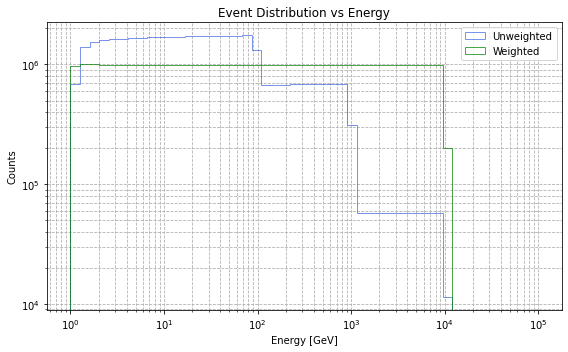

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(df['Etrue'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='royalblue', histtype='step', label='Unweighted', alpha=0.7)
plt.hist(df['Etrue'], weights=df['weight'], bins=np.logspace(np.log10(1), np.log10(1e5), nbins), color='green', histtype='step', label='Weighted', alpha=0.7)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Energy [GeV]")
plt.ylabel("Counts")
plt.title("Event Distribution vs Energy")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.tight_layout()
plt.savefig(figPath + f"energy_spectrum_comparison.png", dpi=400)
plt.show()